## Crop Yield Prediction

A beginner-level regression project that predicts crop yield (hectograms per hectare) across 101 countries and 10 crop types using climate and agricultural input featuees from the FAO/Kaggle dataset.

**Problem Statement:** given country, crop type, year, annual rainfall, pesticide usage and average temperature, predict `hg/ha_yield`. Such a model can support agricultural planning, food-security assessments and resource allocation decisions.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import clone

import warnings
warnings.filterwarnings("ignore")

In [2]:
sns.set_style("whitegrid")
%matplotlib inline


## Load and inspect the data

In [3]:
df = pd.read_csv("yield_df.csv")

In [4]:
df

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.00,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.00,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.00,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.00,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.00,16.37
...,...,...,...,...,...,...,...,...
28237,28237,Zimbabwe,"Rice, paddy",2013,22581,657.0,2550.07,19.76
28238,28238,Zimbabwe,Sorghum,2013,3066,657.0,2550.07,19.76
28239,28239,Zimbabwe,Soybeans,2013,13142,657.0,2550.07,19.76
28240,28240,Zimbabwe,Sweet potatoes,2013,22222,657.0,2550.07,19.76


In [5]:
df.head()

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [6]:
df.tail()

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
28237,28237,Zimbabwe,"Rice, paddy",2013,22581,657.0,2550.07,19.76
28238,28238,Zimbabwe,Sorghum,2013,3066,657.0,2550.07,19.76
28239,28239,Zimbabwe,Soybeans,2013,13142,657.0,2550.07,19.76
28240,28240,Zimbabwe,Sweet potatoes,2013,22222,657.0,2550.07,19.76
28241,28241,Zimbabwe,Wheat,2013,22888,657.0,2550.07,19.76


In [7]:
df.shape

(28242, 8)

In [8]:
df.columns

Index(['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield',
       'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Unnamed: 0                     28242 non-null  int64  
 1   Area                           28242 non-null  str    
 2   Item                           28242 non-null  str    
 3   Year                           28242 non-null  int64  
 4   hg/ha_yield                    28242 non-null  int64  
 5   average_rain_fall_mm_per_year  28242 non-null  float64
 6   pesticides_tonnes              28242 non-null  float64
 7   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(3), str(2)
memory usage: 2.1 MB


**Insight**
- 28,242 rows × 8 columns: 2 text columns (`Area`, `Item`), 3 numeric features plus `Year`, and the target `hg/ha_yield`.
- `Unnamed: 0` is just a leftover row index and carries no information.

## Cleaning

In [10]:
df.isnull().sum()

Unnamed: 0                       0
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

**Insight**
- There are **no missing values** in any column, so the imputers in the preprocessing pipeline are only a safety net for future data.

In [11]:
df = df.drop(columns="Unnamed: 0")

In [12]:
print(df.duplicated().sum())

2310


In [13]:
df = df.drop_duplicates().reset_index(drop=True)

In [14]:
df.shape

(25932, 7)

**Insight**
- **2,310 rows (8.2%) were exact duplicates** and were removed, leaving 25,932 rows.
- Even after that, only **13,130 unique country-crop-year combinations** exist among the 25,932 rows. About half the rows repeat the same yield and pesticide value with a different `avg_temp` (for example, the same country-year can appear with up to 19 different temperatures). So the dataset holds fewer independent observations than its row count suggests.

In [15]:
df.head()

,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


* `Unnamed: 0` is just the old index, so it is dropped.
* Rainfall, prsticides and temperature are recorded **per country-year**, so they repeat across crops. Dropping the index exposes **exact duplicate rows**. Left in, duplicates can land in both train and test sets and inflate the scores.

## Exploratory Data Analysis

In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,25932.0,2001.556455,7.055924,1990.00,1995.00,2001.00,2008.00,2013.00
hg/ha_yield,25932.0,76978.132925,84647.605552,50.00,19996.00,39530.00,104168.00,501412.00
average_rain_fall_mm_per_year,25932.0,1146.836688,717.391098,51.00,593.00,1083.00,1668.00,3240.00
pesticides_tonnes,25932.0,34782.573241,57228.568244,0.04,1597.00,15373.00,45620.00,367778.00
avg_temp,25932.0,20.422251,6.439402,1.30,16.58,21.42,26.06,30.65


In [17]:
df.describe(include='all').round(2)

,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,25932,25932,25932.00,25932.00,25932.00,25932.00,25932.00
unique,101,10,NaN,NaN,NaN,NaN,NaN
top,India,Potatoes,NaN,NaN,NaN,NaN,NaN
freq,3384,3956,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,2001.56,76978.13,1146.84,34782.57,20.42
std,NaN,NaN,7.06,84647.61,717.39,57228.57,6.44
min,NaN,NaN,1990.00,50.00,51.00,0.04,1.30
25%,NaN,NaN,1995.00,19996.00,593.00,1597.00,16.58
50%,NaN,NaN,2001.00,39530.00,1083.00,15373.00,21.42
75%,NaN,NaN,2008.00,104168.00,1668.00,45620.00,26.06


**Insight**
- **Yield:** mean 76,978 vs median 39,530 hg/ha (mean is ~1.9× the median), range 50 to 501,412. A few very productive crops pull the mean up.
- **Pesticides:** mean 34,783 vs median 15,373 tonnes, max 367,778. Highly skewed.
- **Rainfall** spans 51 to 3,240 mm and **temperature** 1.3 to 30.7 °C, so the data covers very dry to very wet and cold to hot countries.
- **Coverage:** 101 countries and 10 crops. India is the most frequent country (3,384 rows, about 13% of the data) and Potatoes the most frequent crop (3,956 rows).

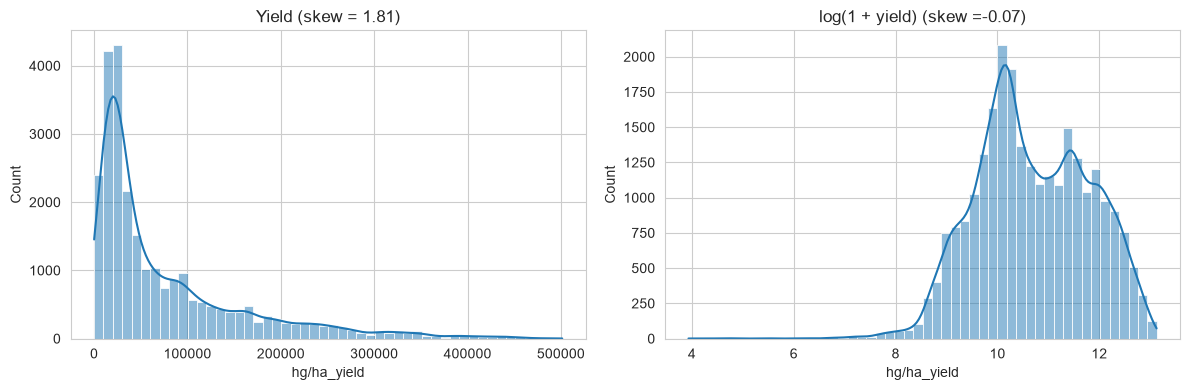

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["hg/ha_yield"], bins = 50, kde=True, ax=ax[0]); ax[0].set_title(f"Yield (skew = {df['hg/ha_yield'].skew():.2f})")
sns.histplot(np.log1p(df["hg/ha_yield"]), bins=50, kde=True, ax=ax[1]); ax[1].set_title(f"log(1 + yield) (skew ={np.log1p(df['hg/ha_yield']).skew():.2f})")
plt.tight_layout()
plt.show()

Yield is strongly right-skewwd. A log transform makes it roughly symmetric, which tends to help linear models.

**Insight**
- Yield skew is **1.81** and drops to **-0.07** after `log1p`, so a log-transformed target would be nearly symmetric.
- 75% of rows are below 104,168 hg/ha but the maximum is 501,412, and about 7% of rows are high-end outliers by the boxplot rule.
- Tree models and KNN are not affected by skew, but the linear models would likely improve with a log target.

In [19]:
order = df.groupby("Item")["hg/ha_yield"].median().sort_values().index

In [20]:
order

Index(['Sorghum', 'Soybeans', 'Wheat', 'Maize', 'Rice, paddy',
       'Plantains and others', 'Yams', 'Sweet potatoes', 'Cassava',
       'Potatoes'],
      dtype='str', name='Item')

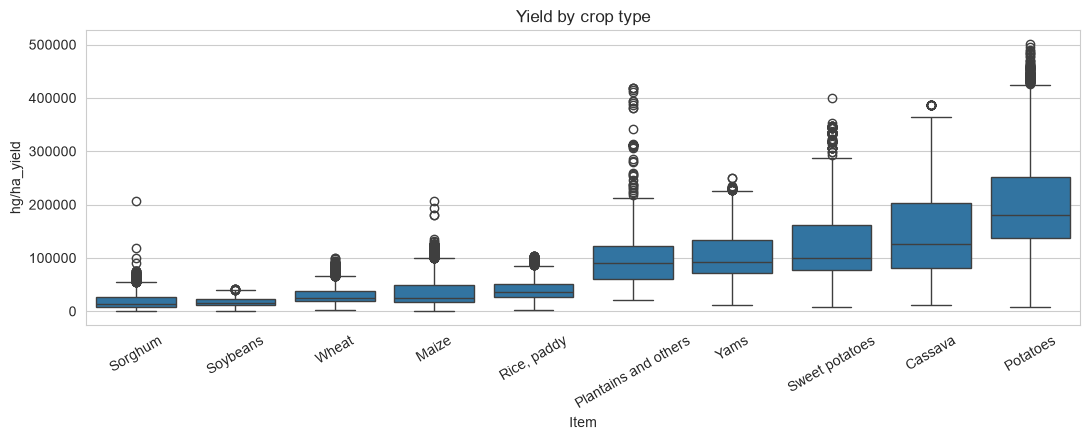

In [21]:
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=df, x="Item", y="hg/ha_yield", order=order)
plt.xticks(rotation=30)
plt.title("Yield by crop type")
plt.tight_layout()
plt.show()

**Insight**
- Crops fall into **two tiers**: cereals and oilseeds (Sorghum, Soybeans, Wheat, Maize, Rice) have median yields of about 13,500 to 36,400 hg/ha, while root crops and plantains (Plantains, Yams, Sweet potatoes, Cassava, Potatoes) have medians of about 90,000 to 180,000.
- **Potatoes** have the highest median (180,322) and the widest spread, up to 501,412.
- Crop type alone explains a large share of the variation, so `Item` will be one of the most important features.

## Univariate Analysis

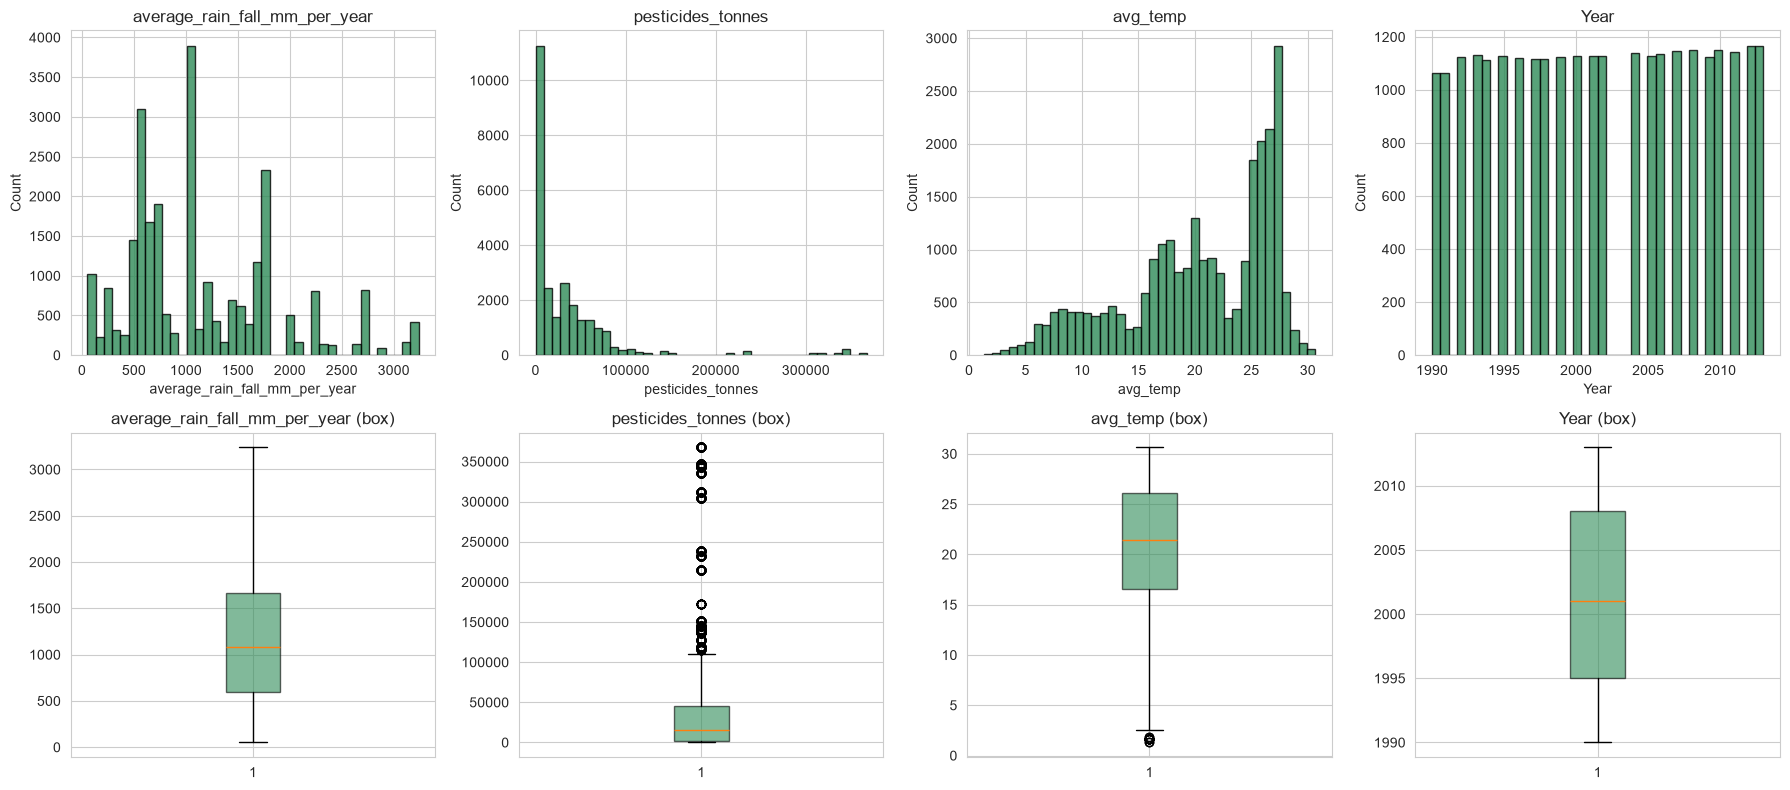

In [22]:
num_features = ['average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'Year']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(num_features):
    axes[0, i].hist(df[col], bins=40, color='seagreen', edgecolor='black', alpha=0.8)
    axes[0, i].set_title(f'{col}')
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel('Count')

    axes[1, i].boxplot(df[col], vert=True, patch_artist=True,
                       boxprops=dict(facecolor='seagreen', alpha=0.6))
    axes[1, i].set_title(f'{col} (box)')

plt.tight_layout()
plt.show()

**Insight**
- **Pesticides** is the most skewed feature (skew 3.64, about 4.9% outliers) with a range from 0.04 to 367,778 tonnes. A few large countries dominate.
- **Rainfall** (skew 0.86, no outliers) and **temperature** (skew -0.71, almost no outliers) are well behaved.
- **Year** is spread evenly across 1990 to 2013, but only 23 distinct years appear because **2003 is missing**.

## Bivariate Analysis

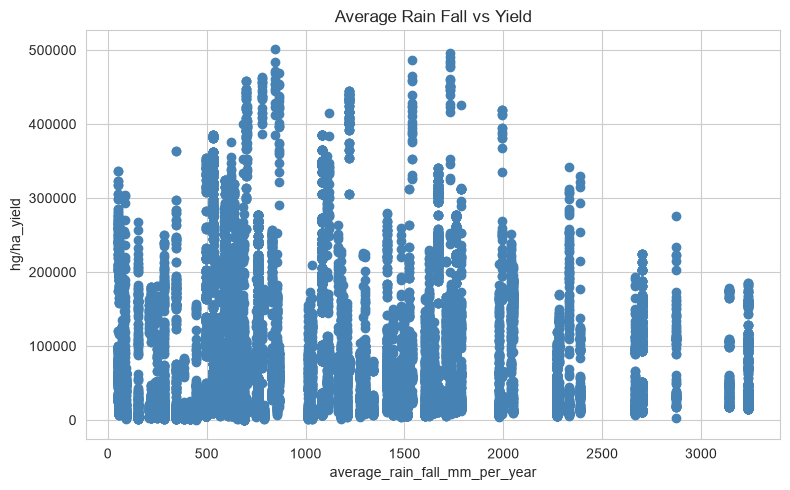

In [23]:
plt.figure(figsize=(8, 5))
plt.scatter(data=df, x="average_rain_fall_mm_per_year", y="hg/ha_yield", color='steelblue')
plt.xlabel("average_rain_fall_mm_per_year")
plt.ylabel('hg/ha_yield')
plt.title("Average Rain Fall vs Yield")
plt.tight_layout()
plt.show()

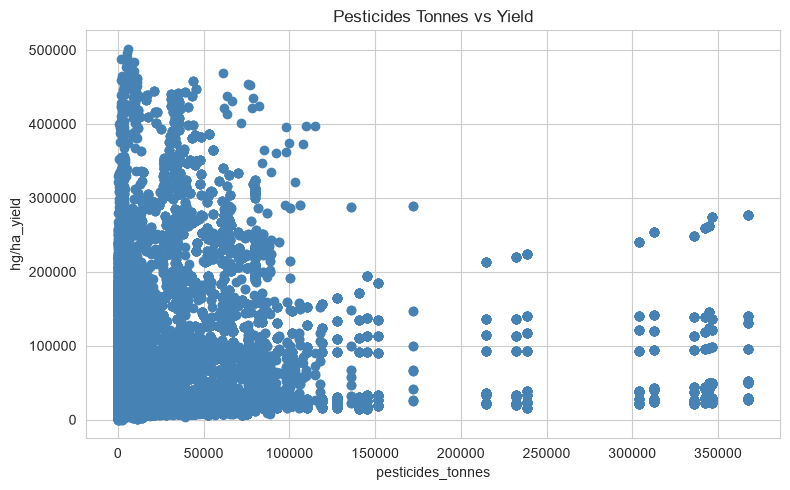

In [24]:
plt.figure(figsize=(8, 5))
plt.scatter(data=df, x="pesticides_tonnes", y="hg/ha_yield", color='steelblue')
plt.xlabel("pesticides_tonnes")
plt.ylabel('hg/ha_yield')
plt.title("Pesticides Tonnes vs Yield")
plt.tight_layout()
plt.show()

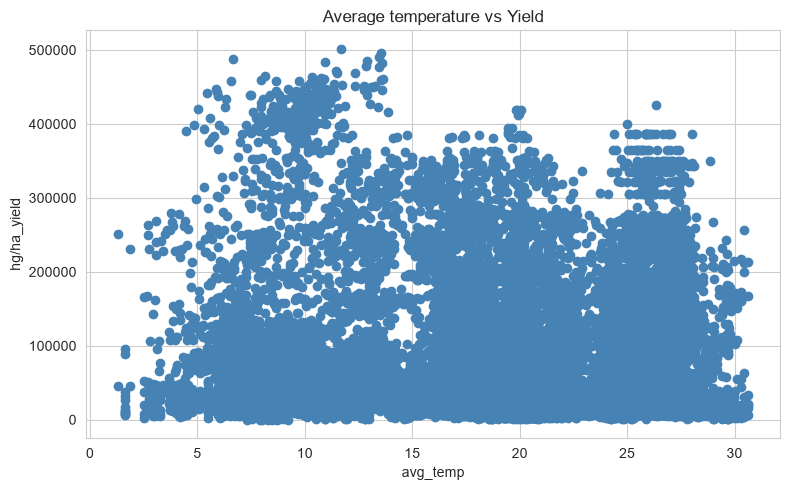

In [25]:
plt.figure(figsize=(8, 5))
plt.scatter(data=df, x="avg_temp", y="hg/ha_yield", color='steelblue')
plt.xlabel("avg_temp")
plt.ylabel('hg/ha_yield')
plt.title("Average temperature vs Yield")
plt.tight_layout()
plt.show()

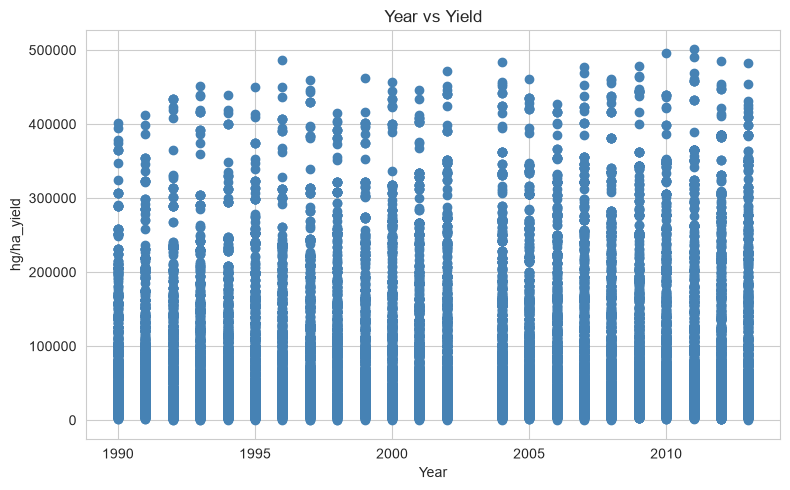

In [26]:
plt.figure(figsize=(8, 5))
plt.scatter(data=df, x="Year", y="hg/ha_yield", color='steelblue')
plt.xlabel("Year")
plt.ylabel('hg/ha_yield')
plt.title("Year vs Yield")
plt.tight_layout()
plt.show()

**Insight**
- **Rainfall:** the points form vertical stripes because every one of the 101 countries has exactly **one** rainfall value for all years. It works like a country label, not a yearly measurement, and has no linear link to yield (r = -0.004).
- **Pesticides:** no linear pattern (r = 0.066). Yields from near 0 to over 400,000 occur at similar pesticide levels, because the value is a national total, not per hectare.
- **Temperature:** only a weak negative link (r = -0.11).
- **Year:** a slight upward drift (r = 0.09), but the spread within each year is huge.
- No single numeric feature explains yield on its own.

In [27]:
mean_by_crop = df.groupby("Item")['hg/ha_yield'].mean().sort_values(ascending=False)
mean_by_crop

Item
Potatoes                198665.725228
Cassava                 145649.692430
Sweet potatoes          119656.515619
Yams                    112105.633075
Plantains and others    106041.320144
Rice, paddy              41296.028470
Maize                    37139.320345
Wheat                    30125.681266
Sorghum                  19099.774729
Soybeans                 16992.190136
Name: hg/ha_yield, dtype: float64

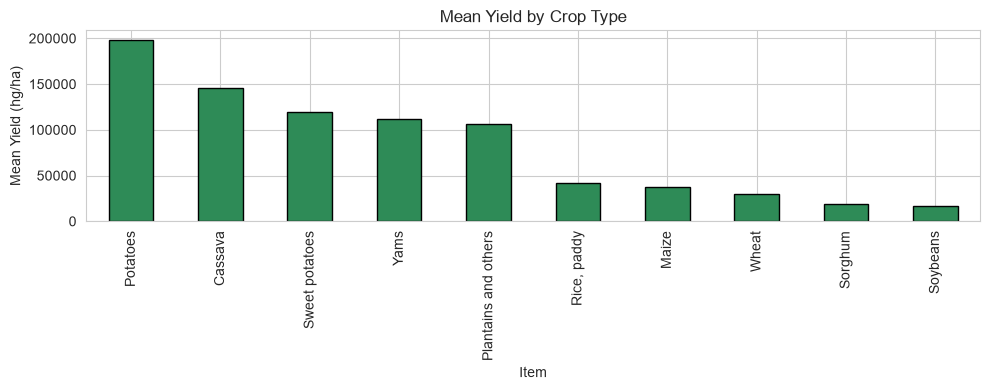

In [28]:
plt.figure(figsize=(10,4))
mean_by_crop.plot(kind='bar', color='seagreen', edgecolor='black')
plt.title("Mean Yield by Crop Type")
plt.ylabel('Mean Yield (hg/ha)')
plt.tight_layout()
plt.show()

**Insight**
- Mean yield for **Potatoes (198,666 hg/ha) is about 11.7× that of Soybeans (16,992)**.
- All five root and tuber crops (Potatoes, Cassava, Sweet potatoes, Yams, Plantains) average above 106,000, while the five cereals and oilseeds stay below 42,000.
- Means are above medians for every crop (for example Maize 37,139 vs 25,557), so each crop has a right tail of unusually productive country-years.

In [29]:
mean_by_country = df.groupby('Area')['hg/ha_yield'].mean().sort_values(ascending=False).head(15)
mean_by_country

Area
United Kingdom    240956.478261
Belgium           216468.461538
Denmark           214033.020000
Netherlands       204151.202899
Ireland           197913.695652
New Zealand       191931.826087
Sweden            187405.500000
Bahrain           153237.551724
Norway            146115.326087
Switzerland       144960.282609
Germany           143631.344444
Finland           135014.521739
Japan             128729.776786
Mauritius         125586.257426
Jamaica           122347.869565
Name: hg/ha_yield, dtype: float64

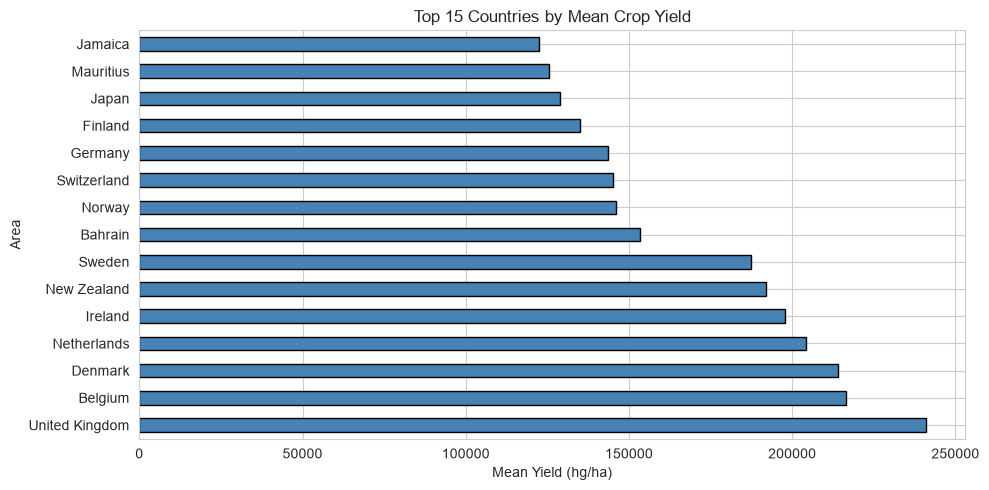

In [30]:
plt.figure(figsize=(10, 5))
mean_by_country.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title("Top 15 Countries by Mean Crop Yield")
plt.xlabel('Mean Yield (hg/ha)')
plt.tight_layout()
plt.show()

**Insight**
- The top 15 is dominated by **developed, mostly European countries**: UK (240,956 hg/ha), Belgium, Denmark, Netherlands and Ireland lead, and 10 of the 15 are European.
- **Crop mix matters:** about half of the UK's rows are potatoes versus 15% overall, and Bahrain only has Potatoes and Sweet potatoes in the data. So a high country mean partly reflects *which crops it grows*, not only farming productivity.
- A fair country comparison should be made within a crop (see the top-country-per-crop table below).

## Correlation Analysis

A heatmap of the numeric features (including the target) revealss linear relationships. Because `Area`  and `item` are categorical, they are excluded here - their impact appears in the bivariate section above.

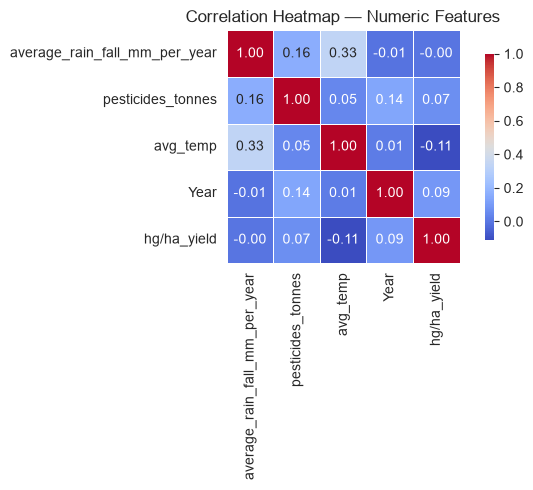


Correlations with hg/ha_yield:
Year                             0.091327
pesticides_tonnes                0.065523
average_rain_fall_mm_per_year   -0.004067
avg_temp                        -0.110400
Name: hg/ha_yield, dtype: float64


In [31]:
num_df = df[['average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'Year', 'hg/ha_yield']]
corr = num_df.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap — Numeric Features')
plt.tight_layout()
plt.show()

print('\nCorrelations with hg/ha_yield:')
print(corr['hg/ha_yield'].drop('hg/ha_yield').sort_values(ascending=False))

**Insight**
- Every numeric feature has a **very weak linear correlation** with yield: temperature -0.110, Year 0.091, pesticides 0.066, rainfall -0.004.
- The features are also barely correlated with each other (the largest is rainfall vs temperature at 0.33), so multicollinearity is not a concern.
- Low correlation does **not** mean the features are useless: the tree-based importances later show they contribute once crop and country are known. Pearson correlation only measures linear relationships, and yield here is driven mainly by the categorical features.

## Domain Deep Dive

Investigate three domain-specific questions:Which crops achieve the highest maximum yields, which countries lead per crop, and how global average yield has trended over the 24-year period.

In [32]:
# Yield trend over years
yearly = df.groupby('Year')['hg/ha_yield'].mean().reset_index()
yearly

,Year,hg/ha_yield
0,1990,66722.149577
1,1991,66496.037629
2,1992,66934.412966
3,1993,67568.484956
4,1994,68371.559353
5,1995,69462.682905
6,1996,69898.326494
7,1997,71120.525561
8,1998,71450.576682
9,1999,73496.134461


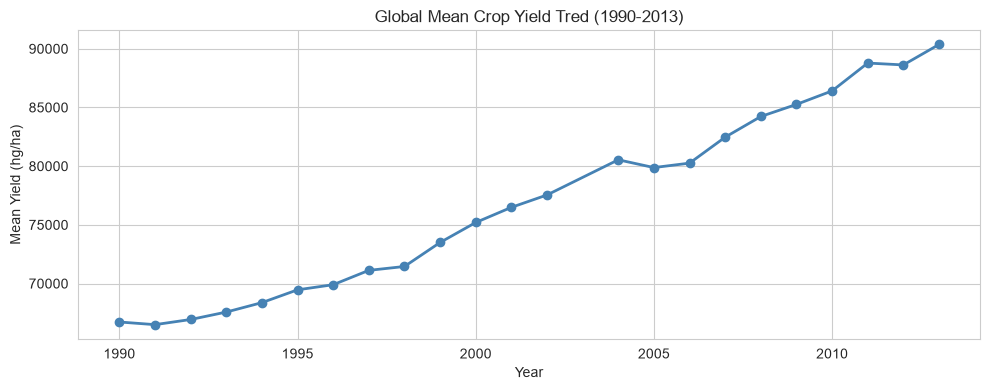

In [33]:
# Yield trend over years
plt.figure(figsize=(10, 4))
plt.plot(yearly['Year'], yearly['hg/ha_yield'], marker='o', color='steelblue', linewidth=2)
plt.title("Global Mean Crop Yield Tred (1990-2013)")
plt.xlabel("Year")
plt.ylabel("Mean Yield (hg/ha)")
plt.tight_layout()
plt.show()

**Insight**
- Global mean yield rose from **66,722 (1990) to 90,362 hg/ha (2013), +35.4%**, roughly 1.3% per year.
- The trend is steady, with only small dips (for example 2005). The line bridges 2002 to 2004 because 2003 is missing.
- This is not just a side effect of which countries are included: the same 510 country-crop pairs present in both 1990 and 2013 show a similar rise (+37.9%).

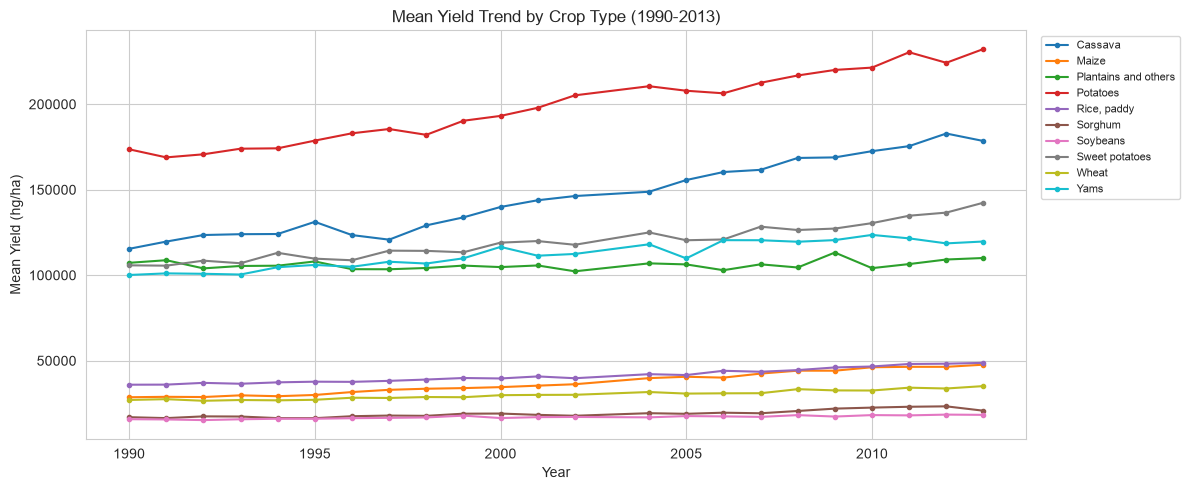

In [34]:
# Yield trend by crop type
pivot = df.groupby(['Year', 'Item'])['hg/ha_yield'].mean().unstack()
plt.figure(figsize=(12,5))
for col in pivot.columns:
    plt.plot(pivot.index, pivot[col], marker='o', markersize=3, linewidth=1.5, label=col)
plt.title('Mean Yield Trend by Crop Type (1990-2013)')
plt.xlabel('Year')
plt.ylabel('Mean Yield (hg/ha)')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

**Insight**
- All crops improved between 1990 and 2013, but unevenly: **Maize +66.5%**, **Cassava +54.6%**, Rice +35.5%, Sweet potatoes +34.6%, Potatoes +33.8%, Wheat +30.0%, Sorghum +22.3%, Yams +19.5%, Soybeans +16.1%.
- **Plantains** are nearly flat (+2.6%).
- The upward drift is why `Year` has a small positive effect in the models, but it is much smaller than the gaps between crops.

In [35]:
# Top country per crop
top_per_crop = df.groupby(['Item', 'Area'])['hg/ha_yield'].mean().reset_index()
top_per_crop = top_per_crop.loc[top_per_crop.groupby('Item')['hg/ha_yield'].idxmax()]
top_per_crop = top_per_crop.sort_values('hg/ha_yield', ascending=False).reset_index(drop=True)
print('Top country per crop (by mean yield):')
print(top_per_crop.to_string(index=False))

Top country per crop (by mean yield):
                Item      Area   hg/ha_yield
            Potatoes   Belgium 448891.538462
Plantains and others Guatemala 291096.304348
             Cassava     India 282957.713948
      Sweet potatoes     Egypt 261369.347826
                Yams     Japan 210897.553571
               Maize     Qatar 136593.000000
         Rice, paddy     Egypt  89234.695652
               Wheat   Belgium  84988.615385
             Sorghum   Austria  63873.250000
            Soybeans     Italy  34446.695652


**Insight**
- Belgium leads Potatoes (448,892 hg/ha) and Wheat, Guatemala leads Plantains, India leads Cassava, Egypt leads Sweet potatoes and Rice, Japan leads Yams.
- **Treat some of these with caution because the samples are small:** Belgium potatoes and wheat have 13 rows each, and Austria sorghum only 4 rows, so those "top" values can be noise. India cassava is backed by 423 rows.
- Leaders are a mix of rich, intensive-farming countries (Belgium, Italy, Austria) and countries with a strong specialisation in that crop (Guatemala, India, Egypt).

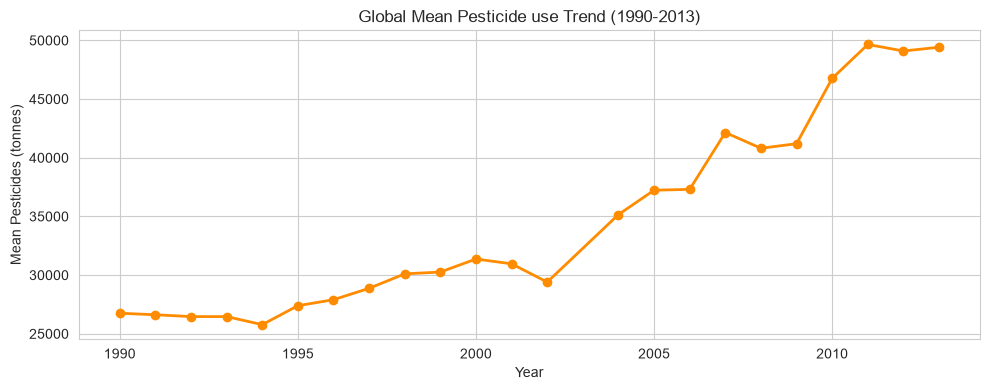

In [36]:
# Pesticide usage trend over years
pest_yearly = df.groupby('Year')['pesticides_tonnes'].mean()
plt.figure(figsize=(10, 4))
pest_yearly.plot(marker ='o', color='darkorange', linewidth=2)
plt.title('Global Mean Pesticide use Trend (1990-2013)')
plt.xlabel('Year')
plt.ylabel("Mean Pesticides (tonnes)")
plt.tight_layout()
plt.show()

**Insight**
- Mean pesticide use rose from **26,747 to 49,415 tonnes (1.85×)** between 1990 and 2013. For the same country-crop pairs in both years the rise is about 2.0×.
- It was roughly flat until 1994, climbed from 1995, jumped around 2004 to 2007 and 2010, and levelled off after 2011.
- Pesticides roughly doubled while yield rose 35%, so both move upward together over time. That is **not proof** that pesticides caused the yield gain, because seeds, irrigation, fertiliser and machinery also changed.

## Summary of Key Findings

The table below distills the most important observation from the EDA into a concise reference for the cleaning.

In [37]:
summary = pd.DataFrame({
    'Finding': [
        'Dataset size',
        'Target skewness',
        'No missing values',
        'No duplicate rows',
        'Highest-yield crop',
        'Lowest-yield crop',
        'Top-yield country',
        'Yield trend',
        'Pesticide trend',
        'Strongest numeric correlation',
    ],
    'Detail': [
        f"{df.shape[0]:,} rows × {df.shape[1]} columns, 101 countries, 10 crops, 1990–2013",
        f"Skew = {df['hg/ha_yield'].skew():.2f} — right-skewed; log-transform could help",
        'No nulls in any column',
        'No exact duplicate rows',
        f"{df.groupby('Item')['hg/ha_yield'].mean().idxmax()} ({df.groupby('Item')['hg/ha_yield'].mean().max():,.0f} hg/ha)",
        f"{df.groupby('Item')['hg/ha_yield'].mean().idxmin()} ({df.groupby('Item')['hg/ha_yield'].mean().min():,.0f} hg/ha)",
        f"{df.groupby('Area')['hg/ha_yield'].mean().idxmax()}",
        'Steady upward trend from 1990 to 2013',
        'Strong upward trend, especially after 2000',
        f"avg_temp (r = {df['hg/ha_yield'].corr(df['avg_temp']):.2f}), but crop type dominates",
    ]
})
summary

,Finding,Detail
0,Dataset size,"25,932 rows × 7 columns, 101 countries, 10 cro..."
1,Target skewness,Skew = 1.81 — right-skewed; log-transform coul...
2,No missing values,No nulls in any column
3,No duplicate rows,No exact duplicate rows
4,Highest-yield crop,"Potatoes (198,666 hg/ha)"
5,Lowest-yield crop,"Soybeans (16,992 hg/ha)"
6,Top-yield country,United Kingdom
7,Yield trend,Steady upward trend from 1990 to 2013
8,Pesticide trend,"Strong upward trend, especially after 2000"
9,Strongest numeric correlation,"avg_temp (r = -0.11), but crop type dominates"


## One-Hot Encoding: Area and Item

In [38]:
cat_cols = ["Area", "Item"]
num_cols = ["Year", "average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]

numerical_cols = Pipeline(steps=[
    ('impute', SimpleImputer(strategy = "median")),
    ('Scaler', StandardScaler())
])

categorical_Cols = Pipeline(steps=[
    ('impute', SimpleImputer(strategy="most_frequent")),
    ('encode', OneHotEncoder(handle_unknown="ignore"))
])

In [39]:
preprocessing = ColumnTransformer([
    ('num', numerical_cols, num_cols),
    ('cat', categorical_Cols, cat_cols)
])

In [40]:
print(f'  Shape: {df.shape}')
print(f'  Aera Unique: {df["Area"].nunique()}')
print(f'  Item Unique: {df["Item"].nunique()}')
print(f'  Ittem Values: {sorted(df["Item"].unique())}')
df_clean = df

  Shape: (25932, 7)
  Aera Unique: 101
  Item Unique: 10
  Ittem Values: ['Cassava', 'Maize', 'Plantains and others', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Wheat', 'Yams']


**Insight**
- After encoding, the model sees **4 numeric + 101 country + 10 crop = 115 columns** (confirmed later in the feature-name check).
- `handle_unknown="ignore"` means a country not seen in training gets all-zero country columns, so the prediction would rely on the crop and the numeric features only.

## Feature Engineering Note

The four original numeric features (`average_rain_fall_mm_per_year`, `pesticides_tonnes`,
`avg_temp`, `Year`) are retained as-is. Because tree-based models (Random Forest, Gradient Boosting)
are scale-invariant, no log-transform is applied here; the StandardScaler in notebook 03 handles
scaling for linear and distance-based models.

A potential future enhancement would be to log-transform the highly right-skewed `pesticides_tonnes`
and the target `hg/ha_yield` for improved linear-model performance.

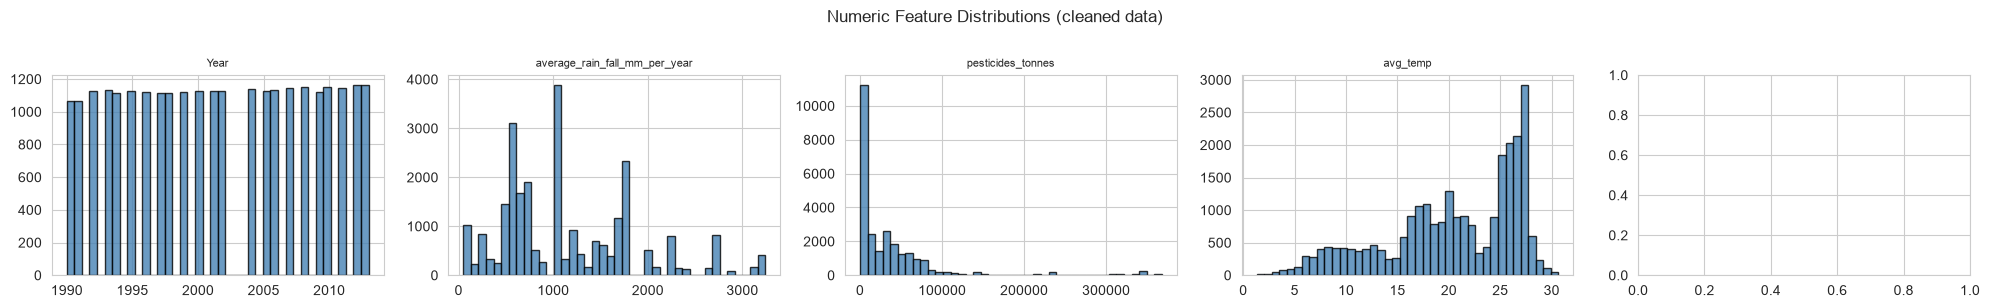

In [41]:
# quick distribution plot numeric features in cleaned datafram
num_col = ['average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'Year']
fig, axes = plt.subplots(1, 5, figsize=(20, 3))
for ax, col in zip(axes, num_cols):
    ax.hist(df_clean[col], bins = 40, color='steelblue', edgecolor = 'black', alpha=0.8)
    ax.set_title(col, fontsize=8)
    ax.set_xlabel('')
plt.suptitle('Numeric Feature Distributions (cleaned data)', y=1.01)
plt.tight_layout()
plt.show()

## Train Test Split and Scaling

We separate the feature (`x`) from the target(`y = hg/ha_yield`), create an 80/20 train/test split with `random_state = 42` for reproducibiity, and fit a `StandardScaler` on the training set only to avoid data leakage.

In [42]:
X = df.drop(columns=['hg/ha_yield'])
y = df['hg/ha_yield']

print(f'Features: {X.shape[1]}')
print(f'Target stats:')
print(y.describe().round(2))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_scaled = preprocessing.fit_transform(X_train)   # fit on train only
X_test_scaled  = preprocessing.transform(X_test)

print(f'\nTrain: {X_train.shape} Test: {X_test.shape}')

Features: 6
Target stats:
count     25932.00
mean      76978.13
std       84647.61
min          50.00
25%       19996.00
50%       39530.00
75%      104168.00
max      501412.00
Name: hg/ha_yield, dtype: float64

Train: (20745, 6) Test: (5187, 6)


**Insight**
- 25,932 rows were split 80/20 into **20,745 train and 5,187 test** rows, using 6 raw features that become 115 encoded columns.
- This is a **random row split**, so for almost every test row the same country, the same crop and often the same year also appear in training (61% of test rows share their exact country-crop-year with a training row). This explains why the non-linear models score so high later. It tests "predict a country we already know", not "predict a new country".

## Model Training 7 Regressors

We trian Linear Regression, Ridge, Lasso, Decision Tree, Random Forest, KNN (with K optimisation), and Gradient Boosting. For each model we call `evaluate_model()` and `plot_prediction()` to compare predicted vs actaul yield on the test set.

In [43]:
results = []
models = {}

In [44]:
def evaluate_model(name, y_true, y_pred, show=True):
    """Compute MAE, RMSE, R2, and MAPE; print them under a banner with the model name."""
    metrics = {
        'Model': name,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
        'MAPE': mean_absolute_percentage_error(y_true, y_pred),
    }
    if show:
        print('=' * 42)
        print(f'  {name}')
        print('=' * 42)
        print(f"  MAE  : {metrics['MAE']:.4f}")
        print(f"  RMSE : {metrics['RMSE']:.4f}")
        print(f"  R2   : {metrics['R2']:.4f}")
        print(f"  MAPE : {metrics['MAPE']:.4f}\n")
    return metrics

def plot_predictions(y_true, y_pred, title):
    """Predicted vs actual scatter with a red dashed 'perfect' line."""
    plt.figure(figsize=(8, 5.5))
    plt.scatter(y_true, y_pred, s=6, alpha=0.3, color='steelblue')
    lim = [0, max(np.max(y_true), np.max(y_pred))]
    plt.plot(lim, lim, 'r--', label='perfect')
    plt.xlabel('Actual yield (hg/ha)')
    plt.ylabel('Predicted yield (hg/ha)')
    plt.title(f'predicted vs Actual - {title}')
    plt.legend()
    plt.tight_layout()

### 1.Linear Regression

  Linear Regression
  MAE  : 29920.7297
  RMSE : 42681.4559
  R2   : 0.7487
  MAPE : 0.8992



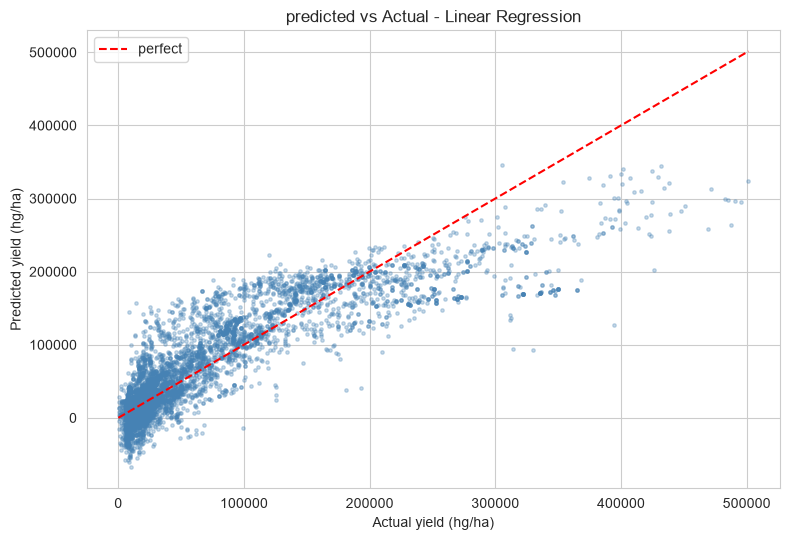

In [45]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)
results.append(evaluate_model('Linear Regression', y_test, y_pred))
models["Linear Regression"] = ('preprocessed', lr)
plot_predictions(y_test, y_pred, 'Linear Regression')
plt.show()

**Insight**
- **R² 0.749, MAE 29,921 hg/ha, MAPE 0.90** (about 90% average percentage error).
- A linear model adds one fixed effect per crop and per country and cannot capture interactions (for example the same rainfall means different things for potatoes and wheat).
- It sets the **baseline** that the non-linear models need to beat.

### 2.Ridge

  Ridge
  MAE  : 29885.3999
  RMSE : 42691.8417
  R2   : 0.7485
  MAPE : 0.8955



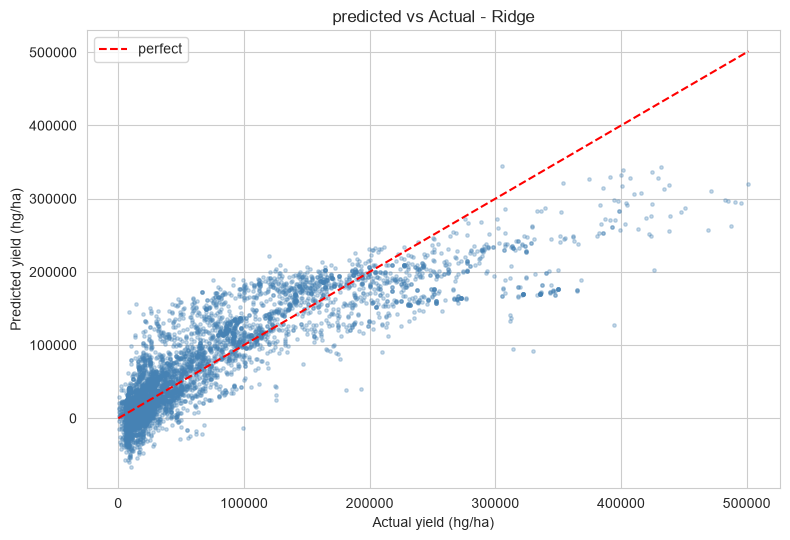

In [46]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred = ridge.predict(X_test_scaled)
results.append(evaluate_model('Ridge', y_test, y_pred))
models['Ridge'] = ('preprocessing', ridge)
plot_predictions(y_test, y_pred, 'Ridge')
plt.show()

**Insight**
- Ridge scores **R² 0.7485**, essentially identical to Linear Regression (0.7487).
- Regularisation does not help because the limit is the linear form, not overfitting or collinear features.

### 3.Lasso

  Lasso
  MAE  : 29905.9082
  RMSE : 42686.3923
  R2   : 0.7486
  MAPE : 0.8970



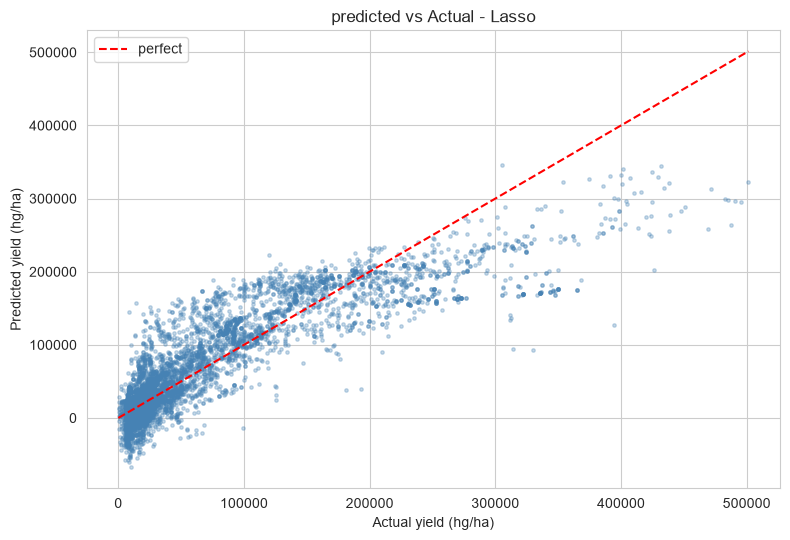

In [47]:
lasso = Lasso(alpha=1.0, max_iter=10000)
lasso.fit(X_train_scaled, y_train)
y_pred = lasso.predict(X_test_scaled)
results.append(evaluate_model('Lasso', y_test, y_pred))
models['Lasso'] = ('preprocessing', lasso)
plot_predictions(y_test, y_pred, 'Lasso')
plt.show()

**Insight**
- Lasso also gives **R² 0.7486**, the same as the other linear models.
- With `alpha=1` and scaled features it removes almost nothing, which again shows the problem is non-linearity, not noise in the features.

### 4.Decision Tree

  Decision Tree
  MAE  : 14028.8770
  RMSE : 23713.2183
  R2   : 0.9224
  MAPE : 0.4569



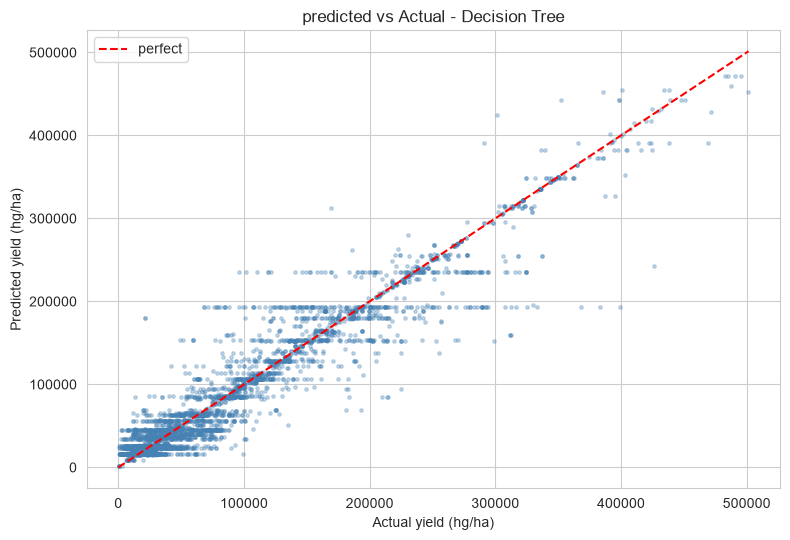

In [48]:
dt = DecisionTreeRegressor(max_depth=10, random_state=42)
dt.fit(X_train_scaled, y_train)
y_pred = dt.predict(X_test_scaled)
results.append(evaluate_model('Decision Tree', y_test, y_pred))
models['Decision Tree'] = ('preprocessing', dt)
plot_predictions(y_test, y_pred, 'Decision Tree')
plt.show()

**Insight**
- A single tree (`max_depth=10`) jumps to **R² 0.922, MAE 14,029**, a gain of about 0.17 over the linear models, because it can split on crop and country interactions.
- It is still behind Random Forest and KNN. The depth limit of 10 holds it back, and in an earlier run a depth-20 tree reached about 0.974.

### 5.Random Forest

  Random Forest
  MAE  : 4020.6967
  RMSE : 10686.8127
  R2   : 0.9842
  MAPE : 0.0856



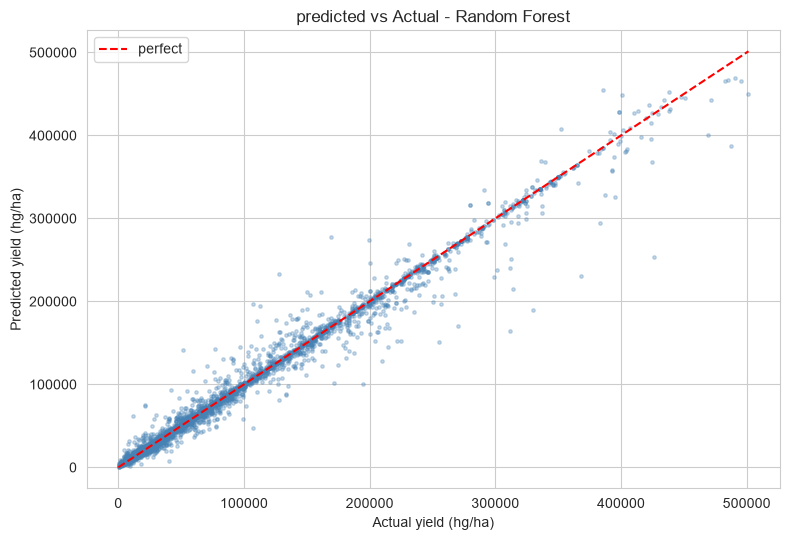

In [49]:
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred = rf.predict(X_test_scaled)
results.append(evaluate_model('Random Forest', y_test, y_pred))
models['Random Forest'] = ('preprocessing', rf)
plot_predictions(y_test, y_pred, 'Random Forest')
plt.show()

**Insight**
- Random Forest reaches **R² 0.984, MAE 4,021 (the lowest of all models) and MAPE 0.086**, so a typical prediction is off by about 8.6%.
- Averaging 200 trees removes most of the single tree's variance (0.922 to 0.984).
- The predicted-vs-actual points sit tightly along the red diagonal.

### 6.KNN (with K optimisation)

The best `k` is chosen by 3-fold cross-validation on the training set only, then evaluated once on the test set.

Best k = 2  (3-fold CV R2 on training set = 0.9835)


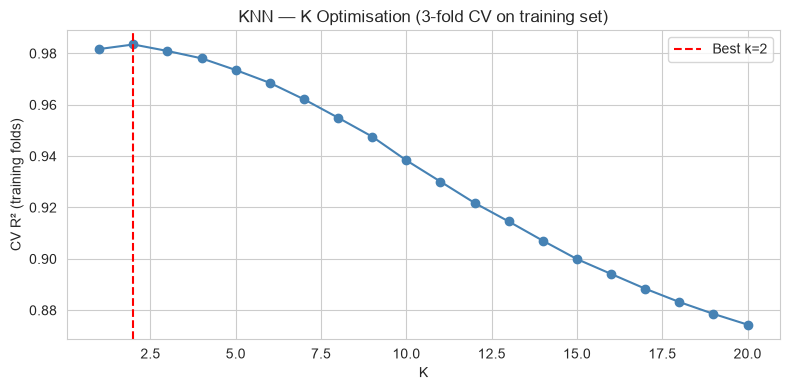

  KNN (k=2)
  MAE  : 4098.4703
  RMSE : 9909.9858
  R2   : 0.9865
  MAPE : 0.0813



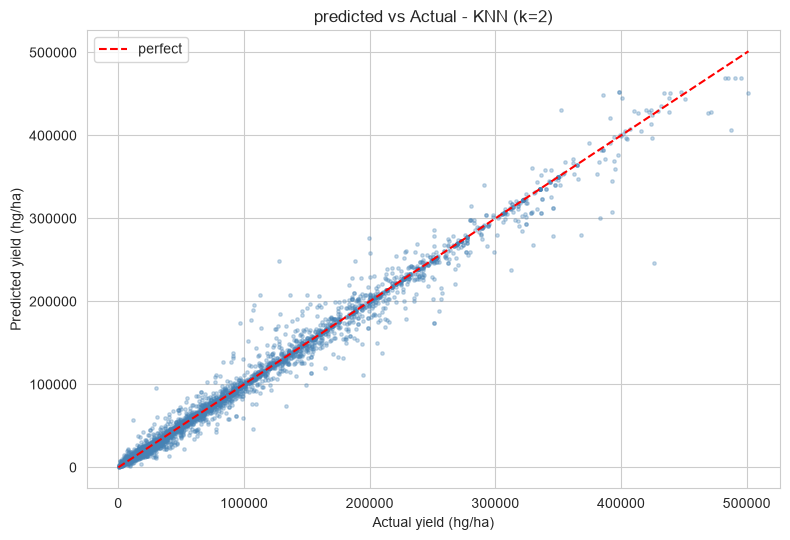

In [50]:
k_range = list(range(1, 21))
knn_search = GridSearchCV(KNeighborsRegressor(n_jobs=-1), {'n_neighbors': k_range},
                          cv=3, scoring='r2')
knn_search.fit(X_train_scaled, y_train)           # only training data is used to pick k
k_scores = knn_search.cv_results_['mean_test_score']
best_k = knn_search.best_params_['n_neighbors']
print(f'Best k = {best_k}  (3-fold CV R2 on training set = {knn_search.best_score_:.4f})')

plt.figure(figsize=(8, 4))
plt.plot(k_range, k_scores, marker='o', color='steelblue')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k={best_k}')
plt.xlabel('K'); plt.ylabel('CV R² (training folds)'); plt.title('KNN — K Optimisation (3-fold CV on training set)')
plt.legend(); plt.tight_layout(); plt.show()

knn = knn_search.best_estimator_                  # already refit on the full training set
y_pred = knn.predict(X_test_scaled)               # the test set is used once, for the final score
knn_label = f'KNN (k={best_k})'
results.append(evaluate_model(knn_label, y_test, y_pred))
models[knn_label] = ('preprocessed', knn)
plot_predictions(y_test, y_pred, knn_label)
plt.show()

**Insight**
- k is chosen by **3-fold CV on the training set only**, with the grid starting at 1, so the test set plays no part in the choice. The best value is **k = 2** (CV R² 0.9835).
- CV R² is almost as high at k = 1 (about 0.982) and then **falls steadily to about 0.87 at k = 20**. A model that prefers the 1 or 2 nearest rows is mostly recalling very similar rows seen in training (same country and crop, nearby values).
- Final KNN on the test set: **R² 0.9865, MAE 4,098, RMSE 9,910, MAPE 0.0813**. These are the best R², RMSE and MAPE of all models.

### 7.Gradient Boosting

  Gradient Boosting
  MAE  : 11888.4214
  RMSE : 19177.9494
  R2   : 0.9493
  MAPE : 0.3449



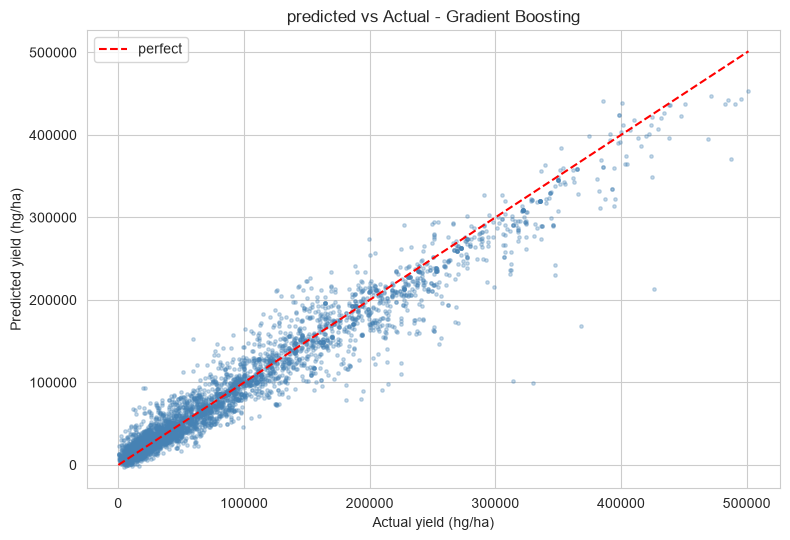

In [51]:
gb = GradientBoostingRegressor(n_estimators=200, max_depth=5, learning_rate=0.1, random_state=42)
gb.fit(X_train_scaled, y_train)
y_pred = gb.predict(X_test_scaled)
results.append(evaluate_model('Gradient Boosting', y_test, y_pred))
models['Gradient Boosting'] = ('preprocessing', gb)
plot_predictions(y_test, y_pred, 'Gradient Boosting')
plt.show()

**Insight**
- Gradient Boosting scores **R² 0.949, MAE 11,888, MAPE 0.345**, clearly behind Random Forest and KNN despite being a more sophisticated method.
- With 200 shallow trees (`max_depth=5`) it underfits the many country-crop combinations that a deep forest can memorise. It was not tuned in this notebook, so its score is a lower bound for what this method can reach.

## Model Comparison

In [52]:
def compare_model(results):
    """True the list of metric dicts into a table sorted by R2 (best first)."""
    return pd.DataFrame(results).sort_values('R2', ascending=False).reset_index(drop=True)

In [53]:
comparison = compare_model(results)
comparison

,Model,MAE,RMSE,R2,MAPE
0,KNN (k=2),4098.470310,9909.985755,0.986450,0.081276
1,Random Forest,4020.696683,10686.812668,0.984243,0.085578
2,Gradient Boosting,11888.421373,19177.949400,0.949255,0.344921
3,Decision Tree,14028.877000,23713.218308,0.922417,0.456941
4,Linear Regression,29920.729705,42681.455888,0.748657,0.899238
5,Lasso,29905.908236,42686.392334,0.748599,0.897017
6,Ridge,29885.399874,42691.841685,0.748535,0.895480


**Insight**
- There are two clear tiers: **linear models at R² of about 0.75** and **non-linear models at 0.92 to 0.986**.
- **KNN (k=2, R² 0.9865) and Random Forest (0.9842) are effectively tied.** KNN has the best RMSE (9,910) and MAPE (0.0813), while Random Forest has the best MAE (4,021).
- Order of the rest: Gradient Boosting (0.949), Decision Tree (0.922), then Linear Regression, Lasso and Ridge (all about 0.7486).
- The big jump from linear to non-linear confirms that yield depends on interactions between crop, country and the numeric features.

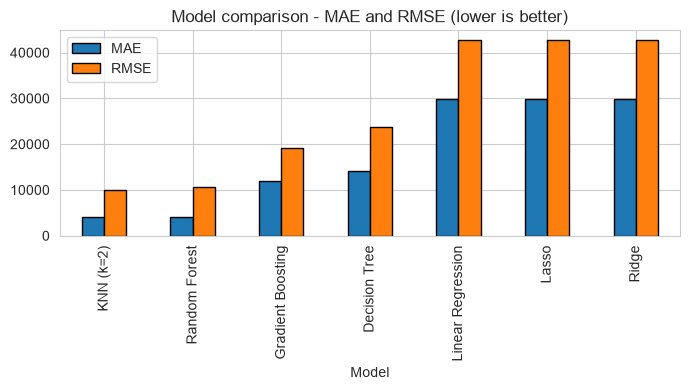

In [54]:
comparison.set_index('Model')[['MAE', 'RMSE']].plot(kind='bar', edgecolor='black', figsize=(7, 4))
plt.xlabel('Model')
plt.title('Model comparison - MAE and RMSE (lower is better)')
plt.tight_layout()
plt.show()

**Insight**
- **Lower is better** for MAE and RMSE (R² is the metric where higher is better).
- For every model RMSE is larger than MAE. The gap is about 2.4× to 2.7× for Random Forest and KNN but only about 1.4× for the linear models. This shows that the best models make small errors on most rows but a few **large misses**, mostly on very high-yield crops.

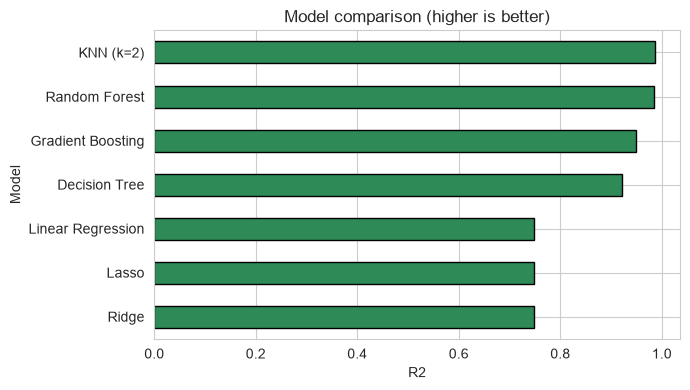

In [55]:
comparison.set_index('Model')['R2'].sort_values().plot(kind='barh', color='seagreen', edgecolor='black', figsize=(7, 4))
plt.xlabel('R2')
plt.title('Model comparison (higher is better)')
plt.tight_layout()
plt.show()

**Insight**
- The R² ranking confirms the table: KNN and Random Forest at the top, a clear step down for Gradient Boosting and Decision Tree, and the three linear models at the bottom with nearly equal bars.

## Feature Importances -- Tree-Bases Model

Tree-based models expose `feature_importances_`, which tell us which features drive the predictions most. The crop type (`Item`) and country (`Aera`) because yield varies encormously across crop and geography.

In [56]:
feature_names = [n.split('__', 1)[1] for n in preprocessing.get_feature_names_out()]   # 'num__Year' -> 'Year'
print(len(feature_names), feature_names[:5])    

115 ['Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'Area_Albania']


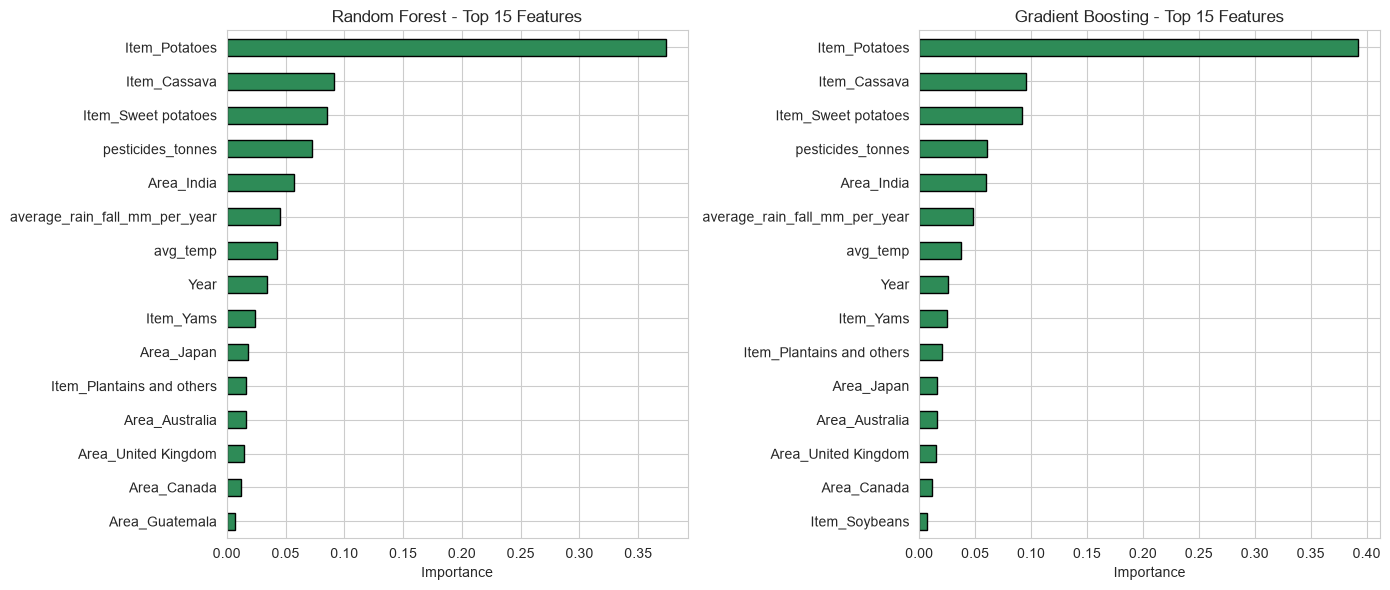

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, model) in zip(axes, [('Random Forest', rf), ('Gradient Boosting', gb)]):
    importances = pd.Series(model.feature_importances_, index=feature_names)
    importances.sort_values().tail(15).plot(kind='barh', ax=ax, color='seagreen', edgecolor='black')
    ax.set_title(f'{name} - Top 15 Features')
    ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

**Insight**
- **Crop type dominates:** `Item_Potatoes` is the single most important feature (about 0.37 in Random Forest and 0.39 in Gradient Boosting), followed by `Item_Cassava` and `Item_Sweet potatoes`. These three crop columns together carry more than half of the importance.
- **`pesticides_tonnes` is the top numeric feature** (about 0.07), ahead of rainfall (about 0.045), temperature (about 0.04) and `Year` (about 0.03).
- **`Area_India`** is the strongest country column, followed by Japan, Australia and the UK.
- One-hot encoding splits country importance across 101 columns, so countries look small individually. In a quick check I grouped importances back to the original columns: `Item` was about 60 to 75%, `Area` about 13 to 20% and the four numeric features about 15 to 20% in total.
- Both models agree closely, which makes these rankings reliable. Do not read the pesticide rank as causal, because it is constant within a country-year and partly acts as a country identifier.

## 5-Fold Cross-Validation

Cross-vaildation gives a more reliable estiamte of generalisation performance than a single train/test split. We run 5-fold CV for every model and display the distribution of R² scores as a box plot.

In [58]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}

for name, (kind, model) in models.items():
    pipe = Pipeline([('prep', clone(preprocessing)), ('model', clone(model))])
    scores = cross_val_score(pipe, X, y, cv=kf, scoring='r2', n_jobs=1)
    cv_scores[name] = scores
    print(f'{name:25s} mean R² = {scores.mean():.4f} (+/- {scores.std():.4f})')

Linear Regression         mean R² = 0.7484 (+/- 0.0018)
Ridge                     mean R² = 0.7484 (+/- 0.0018)
Lasso                     mean R² = 0.7484 (+/- 0.0018)
Decision Tree             mean R² = 0.9266 (+/- 0.0058)
Random Forest             mean R² = 0.9878 (+/- 0.0022)
KNN (k=2)                 mean R² = 0.9873 (+/- 0.0016)
Gradient Boosting         mean R² = 0.9534 (+/- 0.0033)


**Insight**
- Mean 5-fold R²: **Random Forest 0.9878 (±0.0022), KNN (k=2) 0.9873 (±0.0016), Gradient Boosting 0.9534 (±0.0033), Decision Tree 0.9266 (±0.0058)**, and all three linear models **0.7484 (±0.0018)**.
- CV scores are within about 0.005 of the single test-set scores, and the standard deviations are tiny, so the results are **stable and the ranking is not an accident of one split**.
- **Caveat:** shuffled folds still keep every country in the training part. In the unseen-country check in the export section below, holding out entire countries (`GroupKFold` by `Area`) drops the Random Forest to R² of about 0.64. These scores describe countries the model has already seen.

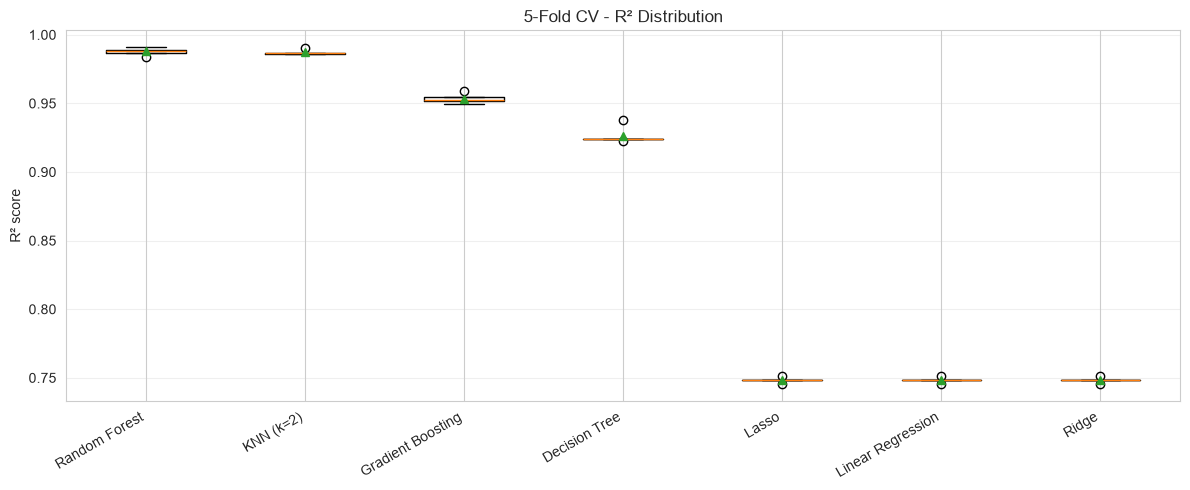

In [59]:
order = sorted(cv_scores, key=lambda k: np.median(cv_scores[k]), reverse=True)

plt.figure(figsize=(12, 5))
plt.boxplot([cv_scores[k] for k in order], tick_labels=order, showmeans=True)   # use labels=order on Matplotlib < 3.9
plt.xticks(rotation=30, ha='right')
plt.ylabel('R² score')
plt.title('5-Fold CV - R² Distribution')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Insight**
- The boxes are very narrow for every model, which shows consistent performance across folds.
- Random Forest (0.9878) and KNN (0.9873) sit at the top and overlap, so they are statistically hard to tell apart. Gradient Boosting and Decision Tree are clearly lower, and the three linear models are indistinguishable.
- Decision Tree has the widest spread (±0.0058), consistent with a single tree being less stable than an ensemble.

## Hyperparameter Tuning — Best Model (GridSearchCV)

In [60]:
# Tune the best tree-based model in the comparison table (KNN was already tuned for k above)
tunable = {
    'Random Forest': (RandomForestRegressor(random_state=42),
                      {'n_estimators': [200, 300], 'max_features': [0.5, 1.0]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=42),
                          {'n_estimators': [200, 300], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5]}),
}
candidates = comparison[comparison['Model'].isin(tunable)]
best_model_name = candidates.iloc[0]['Model']
print(f'Best tree-based model from comparison: {best_model_name}')

base_est, param_grid = tunable[best_model_name]
grid = GridSearchCV(base_est, param_grid, cv=3, scoring='r2', n_jobs=-1, verbose=0)
grid.fit(X_train_scaled, y_train)

print('Best params :', grid.best_params_)
print('Best CV R²  :', round(grid.best_score_, 4))

best = grid.best_estimator_
y_pred_tuned = best.predict(X_test_scaled)
tuned_name = f'{best_model_name} (Tuned)'
tuned_metrics = evaluate_model(tuned_name, y_test, y_pred_tuned)
results.append(tuned_metrics)

Best tree-based model from comparison: Random Forest
Best params : {'max_features': 0.5, 'n_estimators': 300}
Best CV R²  : 0.9837
  Random Forest (Tuned)
  MAE  : 4167.9068
  RMSE : 10631.6234
  R2   : 0.9844
  MAPE : 0.0880



**Insight**
- The cell tunes the **best tree-based model in the comparison table, which is Random Forest**. KNN already had its k tuned above.
- Best setting from the grid: `n_estimators=300, max_features=0.5`, with CV R² 0.9837.
- Test result: **R² 0.9844 vs 0.9842 for the default forest, MAE 4,168 vs 4,021, MAPE 0.0880 vs 0.0856**. Tuning gave **no real gain** (MAE is even slightly worse), so the default Random Forest is already near the ceiling for this data.
- The remaining error comes from the data (national averages, no soil or irrigation information), not from hyperparameters. The grid is small, so this says "no easy gain", not "no possible gain".

## Residual Analysis — Best Model

Residual plots reveal whether our best model's errors are random (desirable) or show systematic patterns. Ideally residuals should be centred near zero with no obvious funnel or curve shape.

In [61]:
def plot_residuals(y_true, y_pred, title):
    """Residuals vs predicted (left) and residual distribution (right)."""
    residuals = np.asarray(y_true) - np.asarray(y_pred)

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

    ax[0].scatter(y_pred, residuals, s=6, alpha=0.3, color='steelblue')
    ax[0].axhline(0, color='r', linestyle='--', label='zero error')
    ax[0].set_xlabel('Predicted yield (hg/ha)')
    ax[0].set_ylabel('Residual (actual - predicted)')
    ax[0].set_title(f'Residuals vs Predicted \u2014 {title}')
    ax[0].legend()

    sns.histplot(residuals, bins=60, kde=True, ax=ax[1], color='seagreen')
    ax[1].axvline(0, color='r', linestyle='--')
    ax[1].set_xlabel('Residual (actual - predicted)')
    ax[1].set_title(f'Residual distribution \u2014 {title}')

    plt.tight_layout()

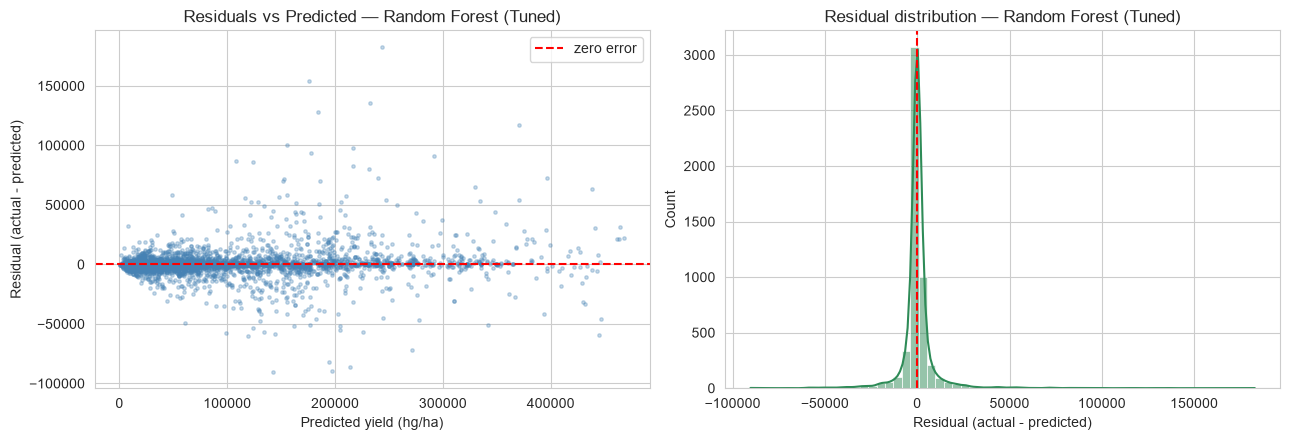

In [62]:
plot_residuals(y_test, y_pred_tuned, tuned_name)
plt.show()

**Insight**
- Residuals form a **very sharp peak at zero**: the tallest bar holds more than half of the 5,187 test rows. There is no overall bias.
- Most points stay within about ±20,000 hg/ha across the range of predicted yields. The spread widens only slightly for high predictions.
- A small number of large misses remain, mostly **positive** (up to about +180,000) and a few negative (down to about -90,000). The model more often under-predicts an exceptional yield than over-predicts one.

## Prediction Example

I run the tuned model on five sample rows from the test set and compare predicted values
with actual yields to give a concrete sense of model accuracy.

In [63]:
sample = X_test_scaled[:5]                  # sparse matrices slice rows with [], not .iloc
preds  = best.predict(sample)

out = pd.DataFrame({
    'Area'              : X_test['Area'].iloc[:5].values,     # X_test is a DataFrame, so .iloc works
    'Item'              : X_test['Item'].iloc[:5].values,
    'Predicted (hg/ha)' : preds.round(0).astype(int),
    'Actual (hg/ha)'    : y_test.iloc[:5].values,
})
out['Abs Error'] = (out['Predicted (hg/ha)'] - out['Actual (hg/ha)']).abs()
out['% Error']   = (out['Abs Error'] / out['Actual (hg/ha)'] * 100).round(2)
out

,Area,Item,Predicted (hg/ha),Actual (hg/ha),Abs Error,% Error
0,Angola,Cassava,129073,155782,26709,17.15
1,Thailand,Soybeans,15499,15787,288,1.82
2,Turkey,Maize,73808,72614,1194,1.64
3,South Africa,Sorghum,21096,30774,9678,31.45
4,Canada,Wheat,28255,28085,170,0.61


**Insight**
- Three of five predictions are very close: Thailand soybeans (1.8% error), Turkey maize (1.6%) and Canada wheat (0.6%).
- Two are under-predicted: Angola cassava (17.2% low) and South Africa sorghum (31.5% low). The large misses are again on the low side.
- The average error on these five rows is 10.5%, in line with the model's overall MAPE of 0.088. Five rows are only an illustration, not a performance estimate.

## Final Summary

In [64]:
final = compare_model(results)
print('Final model rankings:')
final

Final model rankings:


,Model,MAE,RMSE,R2,MAPE
0,KNN (k=2),4098.470310,9909.985755,0.986450,0.081276
1,Random Forest (Tuned),4167.906801,10631.623403,0.984405,0.087988
2,Random Forest,4020.696683,10686.812668,0.984243,0.085578
3,Gradient Boosting,11888.421373,19177.949400,0.949255,0.344921
4,Decision Tree,14028.877000,23713.218308,0.922417,0.456941
5,Linear Regression,29920.729705,42681.455888,0.748657,0.899238
6,Lasso,29905.908236,42686.392334,0.748599,0.897017
7,Ridge,29885.399874,42691.841685,0.748535,0.895480


**Insight**
- **KNN (R² 0.9865), Random Forest tuned (0.9844) and Random Forest default (0.9842) are all within 0.002 of each other**, so treat them as a tie. Gradient Boosting (0.949), Decision Tree (0.922) and the linear models (about 0.749) follow.
- **Recommended final model: the default Random Forest.** It has the best MAE, a stable CV score (0.9878 ± 0.0022), tuning added nothing, and it provides feature importances. KNN reaches the same accuracy only by relying on its 2 nearest neighbours, which is closer to memorisation.

## Overall Conclusions and Caveats

**What the analysis shows**
- **Crop type is the dominant driver of yield.** Root crops and plantains yield about 5 to 12× more per hectare than cereals and oilseeds, and `Item_Potatoes` alone is the top feature.
- **Yield rose 35% from 1990 to 2013** while pesticide use nearly doubled (1.85×). Both trends are clear, but this does not prove a causal link.
- **Non-linear models clearly beat linear ones:** Random Forest and KNN reach R² of about 0.985 with a typical error of about 8 to 9% (MAPE 0.081 to 0.086), versus 0.75 and about 90% for the linear baselines. 5-fold CV confirms the result is stable, and hyperparameter tuning of the forest added nothing.

**Caveats to state when presenting this project**
1. **The data is less independent than its size suggests.** Only 13,130 of 25,932 rows are unique country-crop-year combinations, and rainfall is a single fixed value per country (a country identifier more than a climate measurement).
2. **The scores are for countries the model has seen.** Random splits and shuffled K-fold keep every country in training. In the unseen-country check in the export section (`GroupKFold` by country), Random Forest drops from R² 0.98 to about 0.64, against 0.55 for a crop-average baseline, so the model is much less reliable for a country with no history.
3. Pesticide and climate values are **annual national figures**, not field-level data, and soil, irrigation and fertiliser are missing. Feature importance describes the model, not cause and effect.
4. KNN's best k of 2 (and k = 1 almost as good) points towards memorisation, not generalisation.

**Possible next steps:** evaluate with a train-on-past / test-on-later-years split, add a log-transformed target, add lagged yield features.

## Export for the Streamlit app
The cells below evaluate the deployment model, then save the files the app needs (trained model, cleaned data and metrics) into a `streamlit_app/` folder. Run them after the cells above; no separate training script is needed.

In [65]:
import os, json
import joblib
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import GroupKFold


def make_deploy_pipe():
    """Random Forest wrapped with the notebook's preprocessing (raw DataFrame in, yield out).
    Slightly lighter than the tuned forest above so the saved file stays small enough to deploy."""
    return Pipeline([
        ('pre', clone(preprocessing)),
        ('rf', RandomForestRegressor(n_estimators=100, max_depth=25, min_samples_leaf=2,
                                     max_features=0.5, n_jobs=-1, random_state=42)),
    ])


# 1) Random 80/20 split (the same split used above)
pipe = make_deploy_pipe().fit(X_train, y_train)
pred = pipe.predict(X_test)
random_split = {'r2': float(r2_score(y_test, pred)), 'mae': float(mean_absolute_error(y_test, pred))}

# 2) Unseen countries: whole countries are held out (GroupKFold by Area), plus a crop-average baseline
r2s, maes, base_r2s, base_maes = [], [], [], []
for tr, te in GroupKFold(n_splits=5).split(X, y, groups=df['Area']):
    pr = make_deploy_pipe().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
    crop_mean = y.iloc[tr].groupby(X['Item'].iloc[tr]).mean()
    base = X['Item'].iloc[te].map(crop_mean).fillna(y.iloc[tr].mean())
    r2s.append(r2_score(y.iloc[te], pr));        maes.append(mean_absolute_error(y.iloc[te], pr))
    base_r2s.append(r2_score(y.iloc[te], base)); base_maes.append(mean_absolute_error(y.iloc[te], base))
unseen = {'r2': float(np.mean(r2s)), 'mae': float(np.mean(maes)),
          'baseline_r2': float(np.mean(base_r2s)), 'baseline_mae': float(np.mean(base_maes))}

print(f"Countries seen in training   : R2 = {random_split['r2']:.3f}, MAE = {random_split['mae']:,.0f} hg/ha")
print(f"Countries never seen         : R2 = {unseen['r2']:.3f} (+/- {np.std(r2s):.3f}), MAE = {unseen['mae']:,.0f} hg/ha")
print(f"Crop-average baseline (same) : R2 = {unseen['baseline_r2']:.3f}, MAE = {unseen['baseline_mae']:,.0f} hg/ha")

Countries seen in training   : R2 = 0.982, MAE = 4,829 hg/ha
Countries never seen         : R2 = 0.640 (+/- 0.043), MAE = 29,712 hg/ha
Crop-average baseline (same) : R2 = 0.546, MAE = 35,636 hg/ha


**Insight**
- The deployment forest scores **R² 0.982 (MAE about 4,829 hg/ha)** on the random 80/20 split, the same level as the models above.
- When **whole countries are held out** (5-fold `GroupKFold` by `Area`), R² falls to **0.640 (±0.043)** and MAE rises to about 29,700 hg/ha. A simple crop-average baseline scores **0.546** on the same folds.
- So for a country with no history, the model is only moderately better than "predict the crop's average yield". The high scores earlier in the notebook describe countries the model has already seen, because country and crop identity carry most of the signal.

In [66]:
out_dir = 'streamlit_app'
os.makedirs(out_dir, exist_ok=True)

# Final model: the deployment pipeline fitted on all cleaned rows
final_pipe = make_deploy_pipe().fit(X, y)

# Feature importance of the final model, grouped back to the original columns
names = [n.split('__', 1)[1] for n in final_pipe.named_steps['pre'].get_feature_names_out()]
imp = pd.Series(final_pipe.named_steps['rf'].feature_importances_, index=names)
group = lambda f: 'Country' if f.startswith('Area_') else 'Crop' if f.startswith('Item_') else f
labels = {'average_rain_fall_mm_per_year': 'Rainfall', 'pesticides_tonnes': 'Pesticides', 'avg_temp': 'Temperature'}
importance = {labels.get(k, k): float(v) for k, v in imp.groupby(group).sum().items()}

# Save everything the app loads
joblib.dump(final_pipe, f'{out_dir}/crop_yield_model.pkl', compress=3)
df.to_csv(f'{out_dir}/yield_clean.csv', index=False)
with open(f'{out_dir}/model_meta.json', 'w') as f:
    json.dump({'random_split': random_split, 'unseen_countries': unseen, 'importance': importance,
               'n_rows': int(len(df)), 'n_trees': 100}, f, indent=1)

print('Saved to:', os.path.abspath(out_dir))
for fn in sorted(os.listdir(out_dir)):
    print(f'  {fn:22s} {os.path.getsize(os.path.join(out_dir, fn)) / 1e6:6.1f} MB')
print(f'\nUse this line in requirements.txt:  scikit-learn=={sklearn.__version__}')

Saved to: c:\Users\ramvi\Downloads\Crop yield\streamlit_app
  crop_yield_model.pkl     19.3 MB
  model_meta.json           0.0 MB
  yield_clean.csv           1.3 MB

Use this line in requirements.txt:  scikit-learn==1.9.1
